In [1]:
import wfdb

record = wfdb.rdrecord(r'D:\mitdb\100')
ann    = wfdb.rdann(r'D:\mitdb\100', 'atr')

ecg   = record.p_signal[:, 0]
fs    = record.fs
r_ref = ann.sample

print(f"采样率: {fs} Hz, 信号长度: {len(ecg)} 点")



采样率: 360 Hz, 信号长度: 650000 点


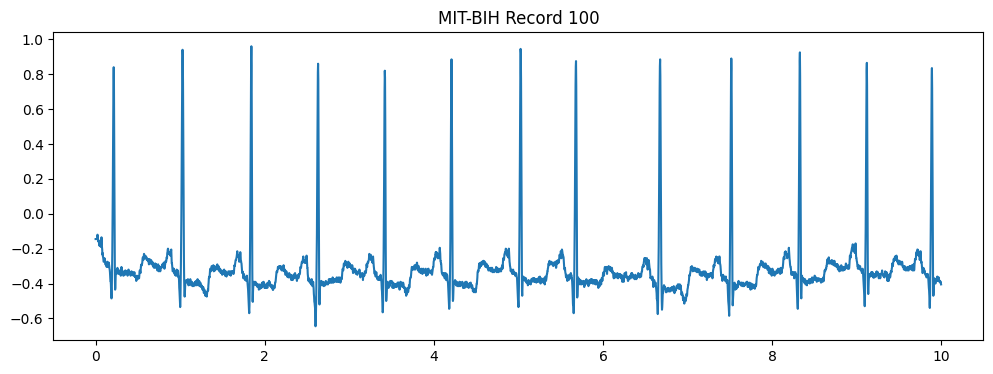

In [2]:
import matplotlib.pyplot as plt
import numpy as np

t = np.arange(int(10*fs)) / fs
plt.figure(figsize=(12, 4))
plt.plot(t, ecg[:int(10*fs)])
plt.title('MIT-BIH Record 100')
plt.show()


In [1]:
import scipy.signal as signal

def design_filters(fs):
    # 1) 0.5Hz 二阶Butterworth高通：去基线漂移
    b_hp, a_hp = signal.butter(2, 0.5, btype='highpass', fs=fs)
    # 2) 50Hz 陷波：去工频（Q越大陷波越窄，30是常用值）
    b_notch, a_notch = signal.iirnotch(50, Q=30, fs=fs)
    # 3) 40Hz 二阶低通：去肌电等高频噪声
    b_lp, a_lp = signal.butter(2, 40, btype='lowpass', fs=fs)
    return (b_hp, a_hp), (b_notch, a_notch), (b_lp, a_lp)

def preprocess_ecg(ecg, fs):
    (b_hp, a_hp), (b_notch, a_notch), (b_lp, a_lp) = design_filters(fs)
    # filtfilt = 正向滤一遍 + 反向滤一遍 → 零相位失真
    # 关键点：普通filter会让QRS波形移位变形，filtfilt不会
    x = signal.filtfilt(b_hp,  a_hp,  ecg)
    x = signal.filtfilt(b_notch, a_notch, x)
    x = signal.filtfilt(b_lp,  a_lp,  x)
    return x

ecg_filt = preprocess_ecg(ecg, fs)
print('滤波完成，信号长度:', len(ecg_filt))


NameError: name 'ecg' is not defined